# Hand-written digits recognition

## My story

One year ago, while taking the *Introduction to Information Technology* course at HCMUS, I had to implement a small team project on hand-written digit recognition.

At that time, my team did not know anything about Machine Learning, so we built a simple model using the KNN algorithm. The results were very poor, specifically, it not only took a significantly long time to train and test but also gave low prediction accuracy. I do not remember the exact accuracy, but I recall feeling really disappointed.

After a year, I have learned a lot of useful concepts in Machine Learning and Deep Learning. Now, I am back with a modern approach to this project. Specifically, I built a CNN model, I also experimented with a ViT model, but its accuracy was not as high as the CNN's. Consequently, I decided to demonstrate my CNN model for this **Hand-written digits recognition** project.

The process includes loading the dataset, preprocessing the images, building a CNN, training it, and evaluating its performance.

## Dataset

The model uses the [MNIST](https://www.kaggle.com/datasets/hojjatk/mnist-dataset) dataset for all training, validation, and testing processes.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

# Load MNIST data
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values to [0, 1]
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape to (num_samples, 28, 28, 1)
x_train_full = np.expand_dims(x_train_full, -1)
x_test = np.expand_dims(x_test, -1)

# Split into Train/Val sets
val_split = 0.1 # Take 10% for the val set
split_idx = int(len(x_train_full) * (1 - val_split))

x_train, x_val = x_train_full[:split_idx], x_train_full[split_idx:]
y_train, y_val = y_train_full[:split_idx], y_train_full[split_idx:]

print(f"Training set shape: {x_train.shape}")
print(f"Validation set shape: {x_val.shape}")
print(f"Test set shape: {x_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training set shape: (54000, 28, 28, 1)
Validation set shape: (6000, 28, 28, 1)
Test set shape: (10000, 28, 28, 1)


## Define Residual Block (inspired by ResNet)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

# Define a Residual Block helper
def residual_block(x, filters, downsample=False):
    shortcut = x
    stride = 2 if downsample else 1

    # 1st convolution of the block
    y = layers.Conv2D(filters, (3, 3), strides=stride, padding='same', kernel_regularizer=regularizers.l2(1e-4))(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation('relu')(y)

    # 2nd convolution of the block
    y = layers.Conv2D(filters, (3, 3), strides=1, padding='same', kernel_regularizer=regularizers.l2(1e-4))(y)
    y = layers.BatchNormalization()(y)

    # Match shortcut dimensions
    if downsample or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1, 1), strides=stride, padding='same', kernel_regularizer=regularizers.l2(1e-4))(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    y = layers.add([y, shortcut])
    y = layers.Activation('relu')(y)
    return y

inputs = layers.Input(shape=(28, 28, 1))

# Layer 1: Initial Convolution
x = layers.Conv2D(32, (3, 3), padding='same', kernel_regularizer=regularizers.l2(1e-4))(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)

# Layers 2-11: 5 Residual Blocks
x = residual_block(x, 32)
x = residual_block(x, 64, downsample=True)
x = residual_block(x, 64)
x = residual_block(x, 128, downsample=True)
x = residual_block(x, 128)

# Layer 12: Dense output classifier layer after pooling
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_cnn = models.Model(inputs=inputs, outputs=outputs, name='12_Layer_ResNet')
model_cnn.summary()

Model: "12_Layer_ResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 28,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 28, 28,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 28, 28,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 28, 28,    │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 28, 28,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 28, 28,    │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 28, 28,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 14, 14,    │     18,496 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 14, 14,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 14, 14,    │     36,928 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 14, 14,    │      2,112 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        256 │ conv2d_4[0][0]  

 Total params: 680,650 (2.60 MB)

 Trainable params: 678,538 (2.59 MB)

 Non-trainable params: 2,112 (8.25 KB)

## Train the model

In [ ]:
model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
]

history = model_cnn.fit(
    x_train, y_train,
    epochs=15,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=callbacks
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 51ms/step - accuracy: 0.9624 - loss: 0.2229 - val_accuracy: 0.8300 - val_loss: 0.6745 - learning_rate: 0.0010
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9883 - loss: 0.1174 - val_accuracy: 0.9873 - val_loss: 0.1148 - learning_rate: 0.0010
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9906 - loss: 0.0973 - val_accuracy: 0.9172 - val_loss: 0.3018 - learning_rate: 0.0010
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9911 - loss: 0.0859 - val_accuracy: 0.9587 - val_loss: 0.1922 - learning_rate: 0.0010
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9955 - loss: 0.0646 - val_accuracy: 0.9902 - val_loss: 0.0763 - learning_rate: 5.0000e-04
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9959 - loss: 0.0564 - val_accuracy: 0.9820 - val_loss: 0.0972 - learning_rate: 5.0000e-04
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9956 - loss:

## Plot Training and Validation Loss/Accuracy

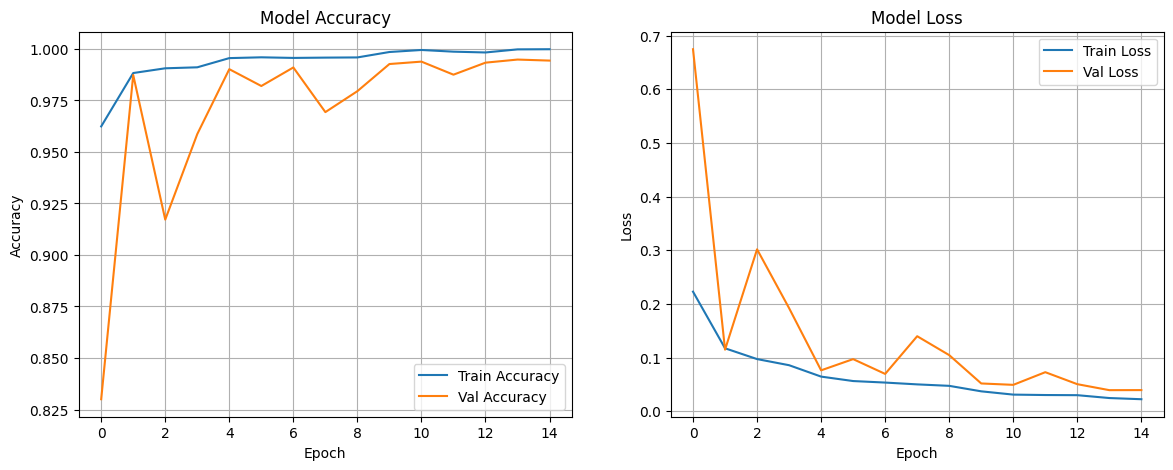

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss plot
axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.show()

## Evaluate the trained model on the Test set

In [ ]:
test_loss, test_acc = model_cnn.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9951
Test Loss: 0.0386


## Visualize Feature Maps

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


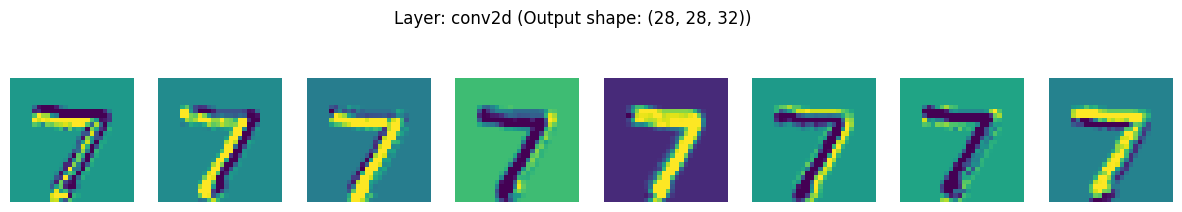

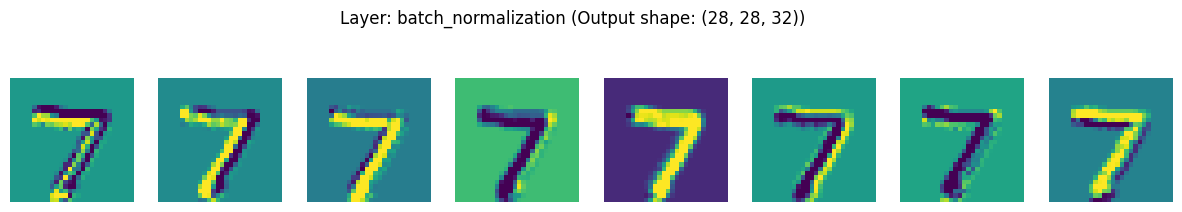

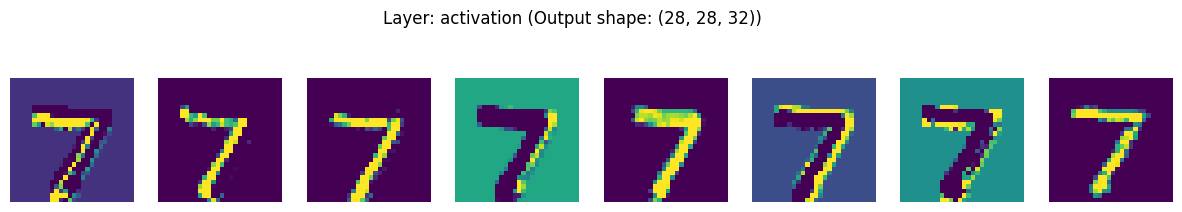

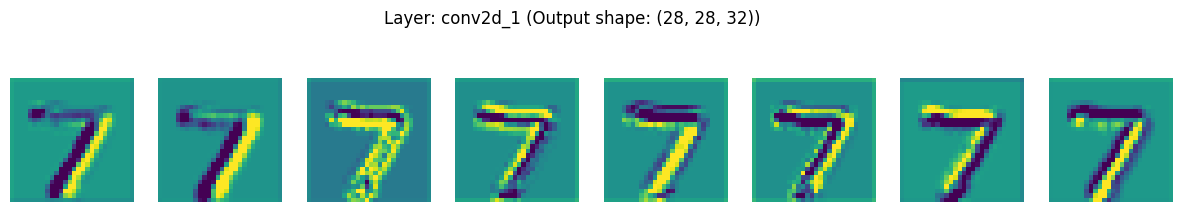

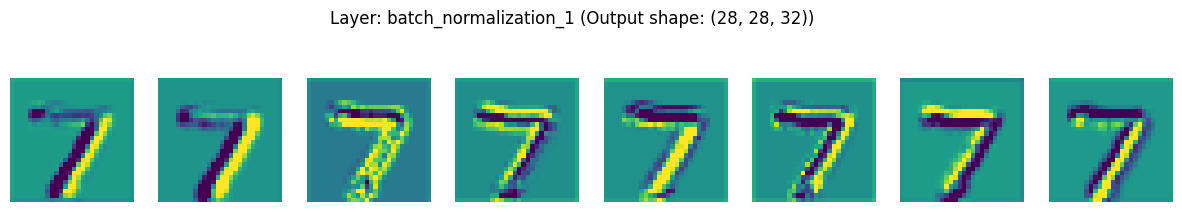

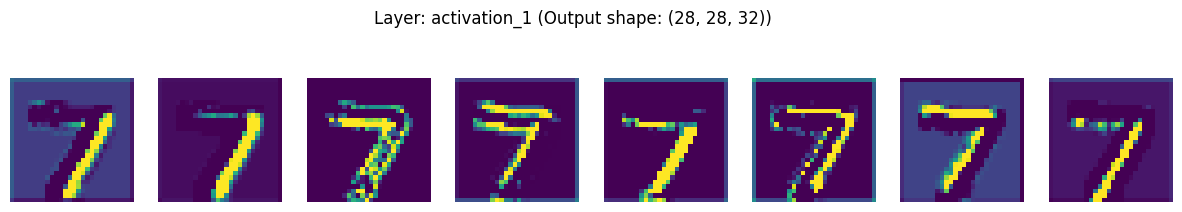

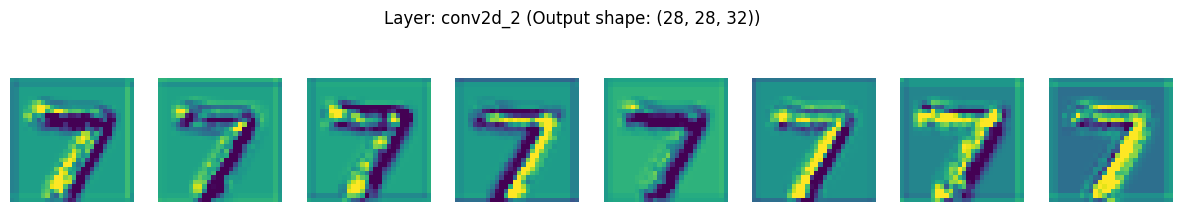

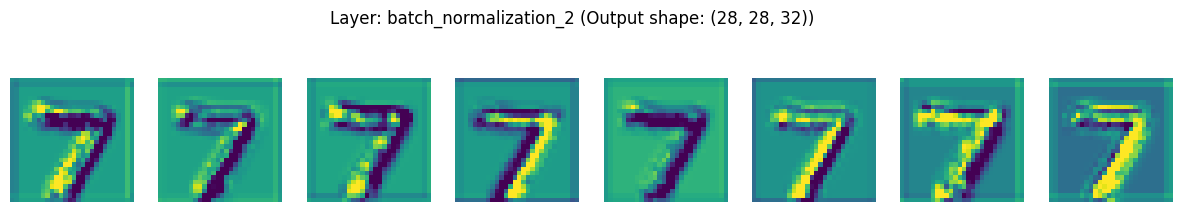

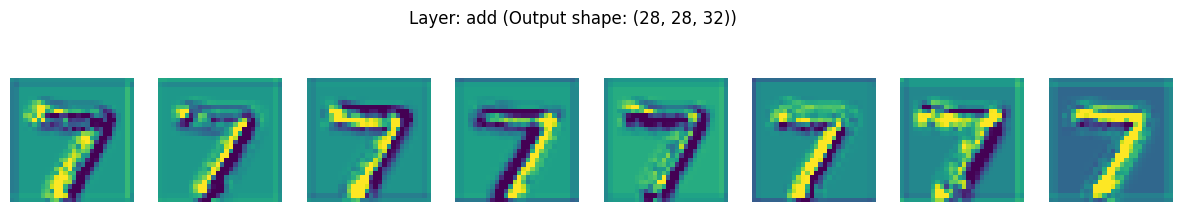

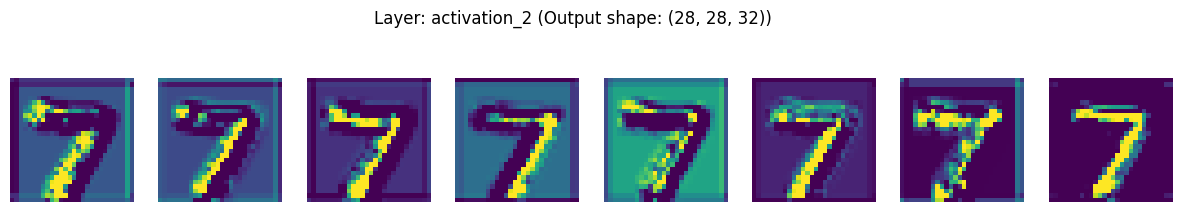

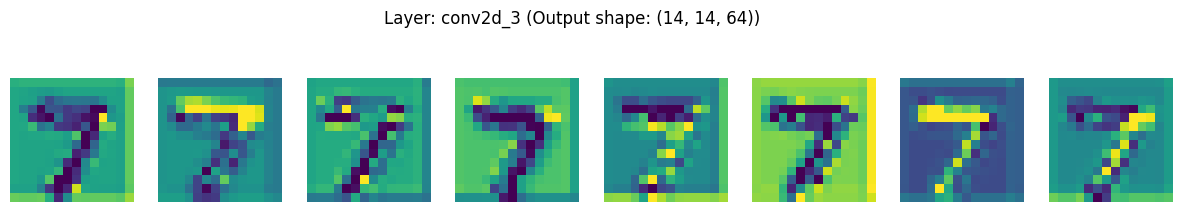

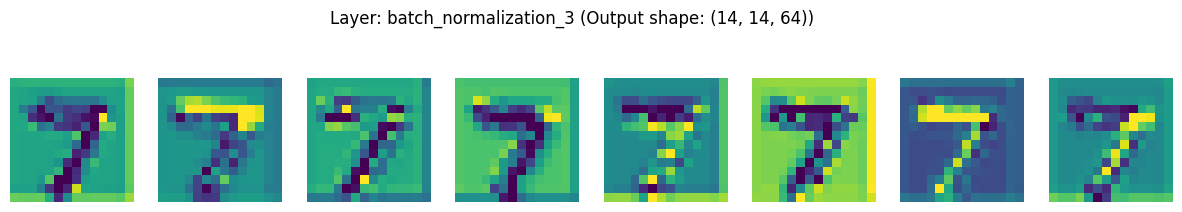

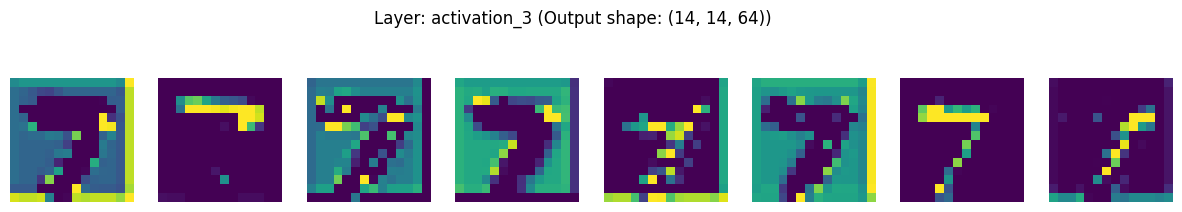

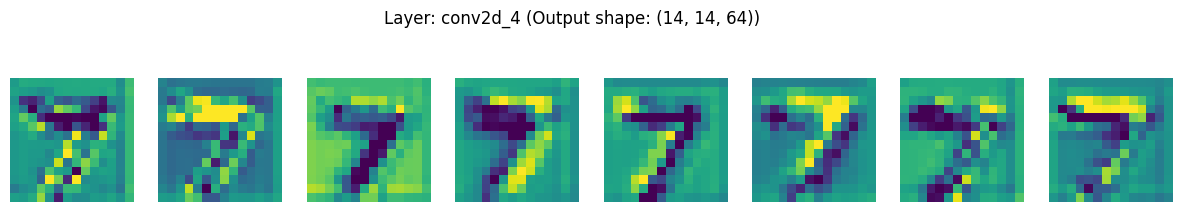

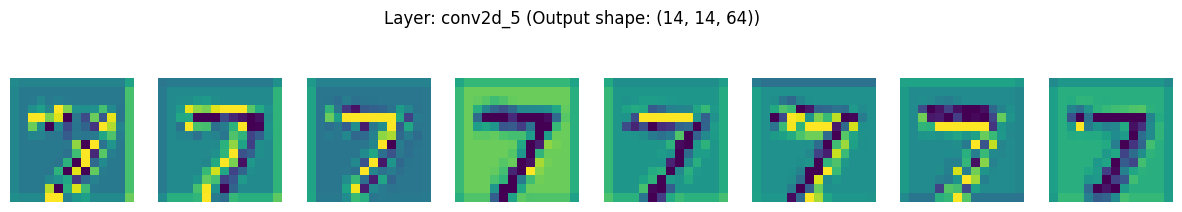

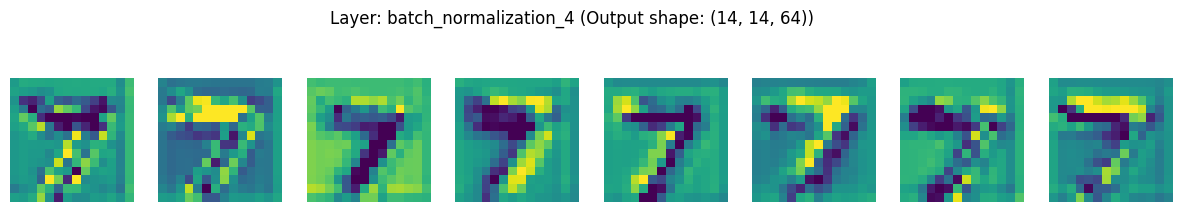

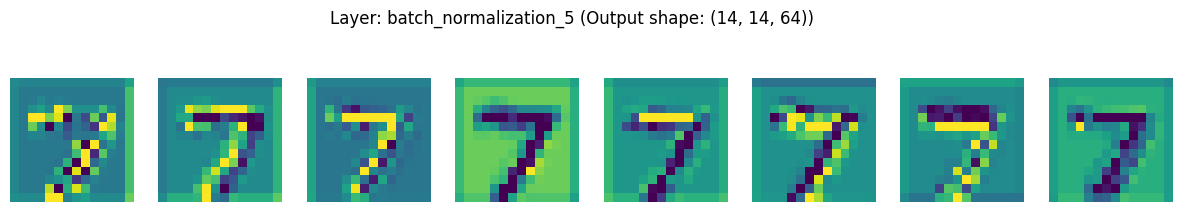

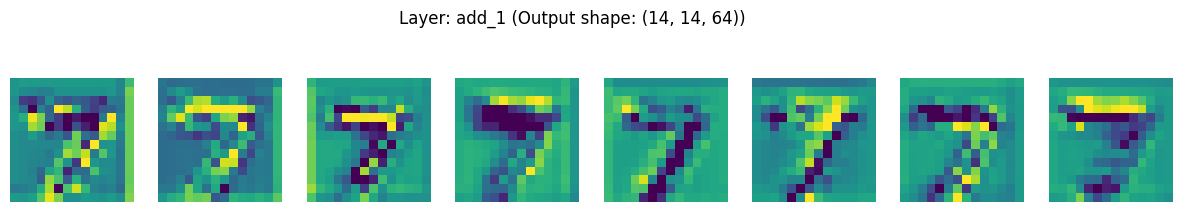

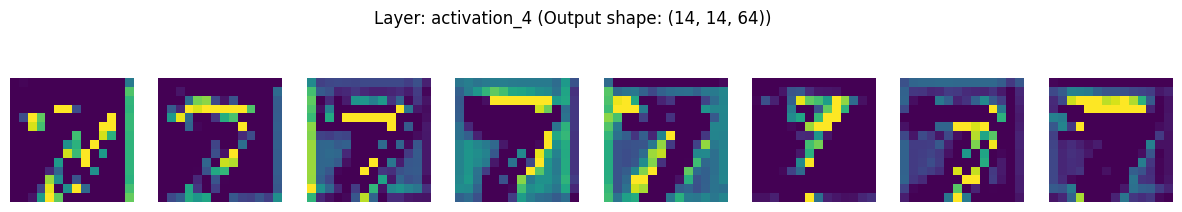

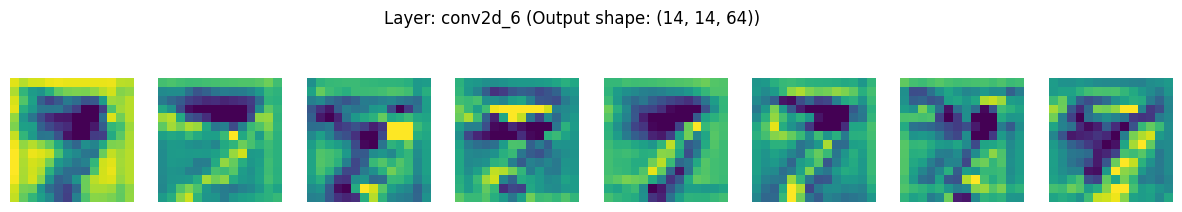

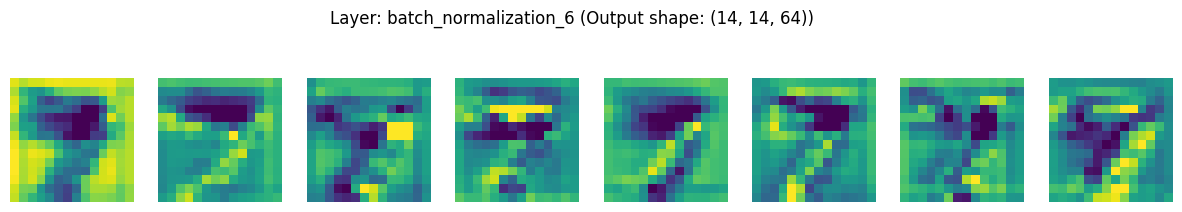

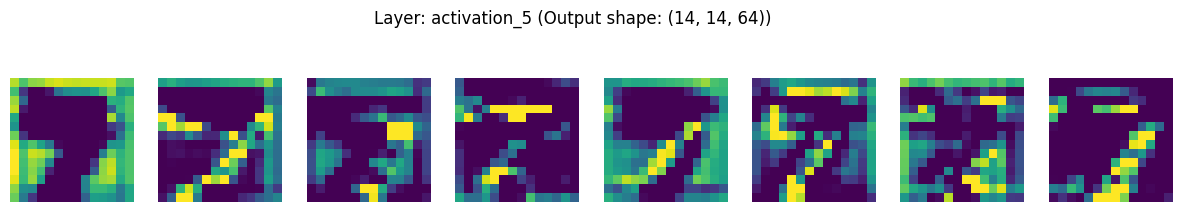

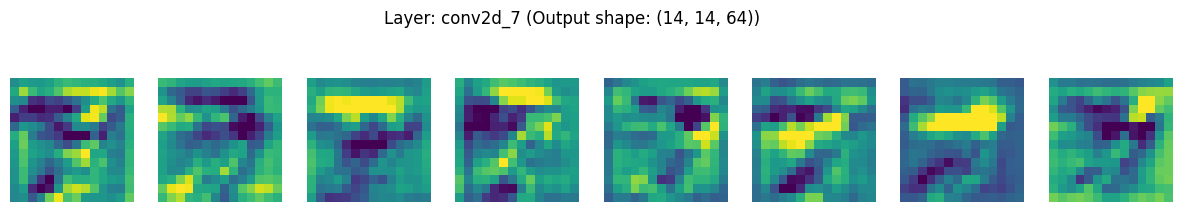

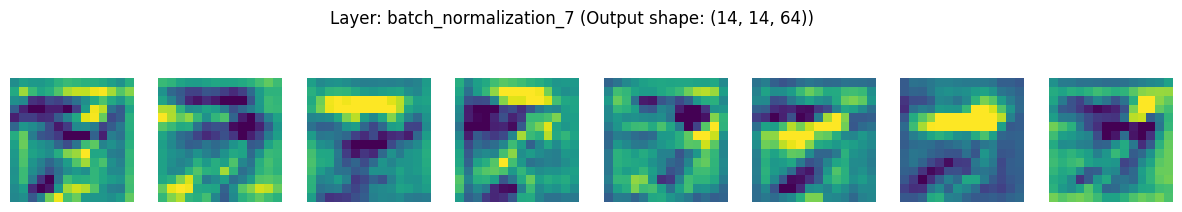

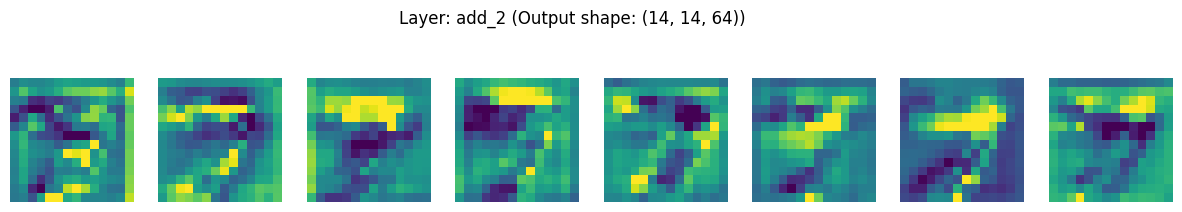

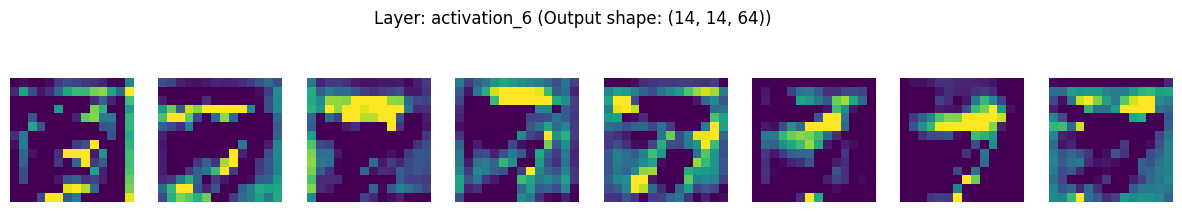

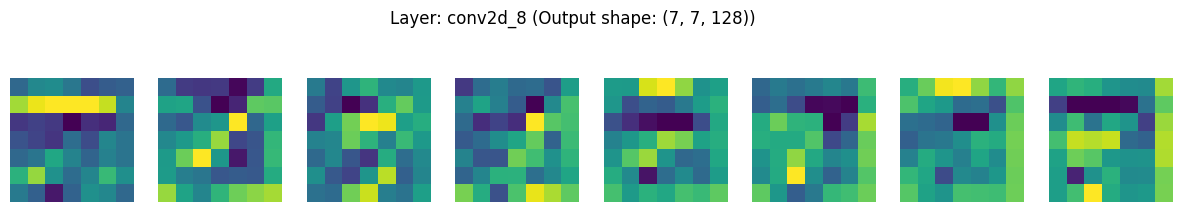

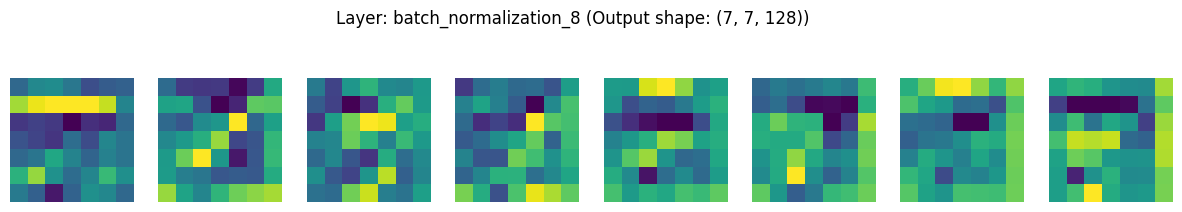

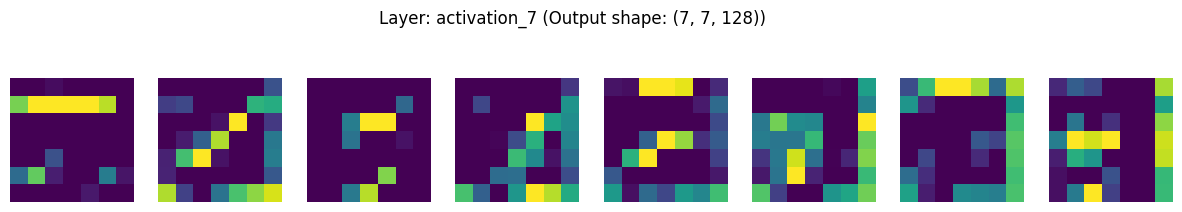

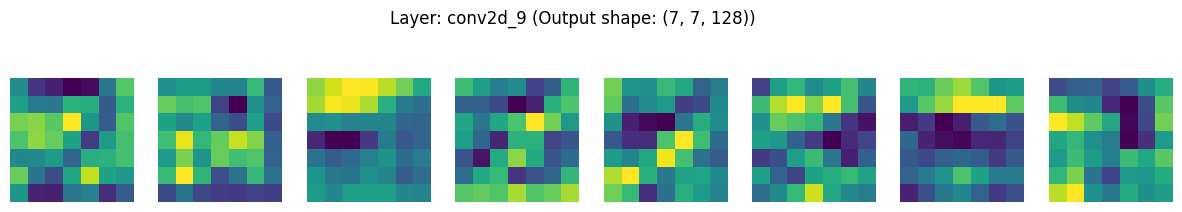

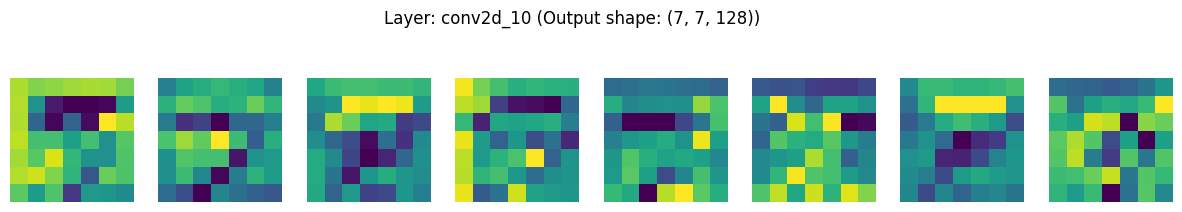

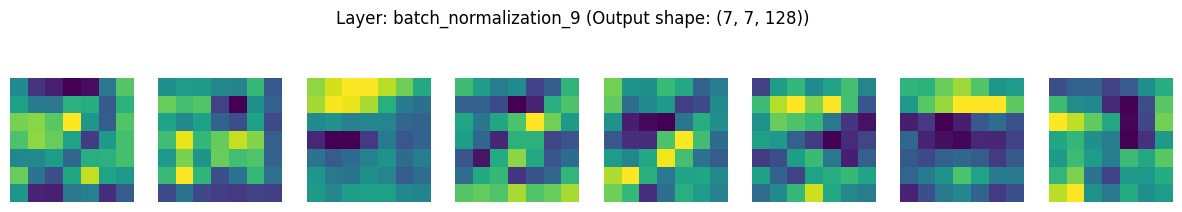

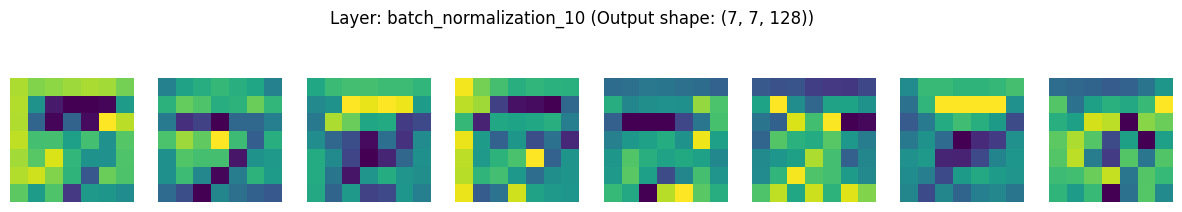

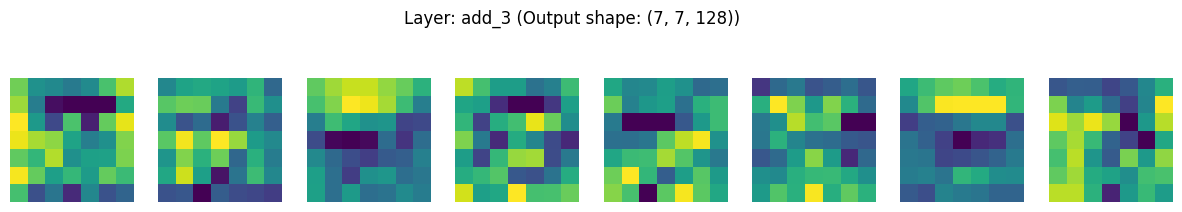

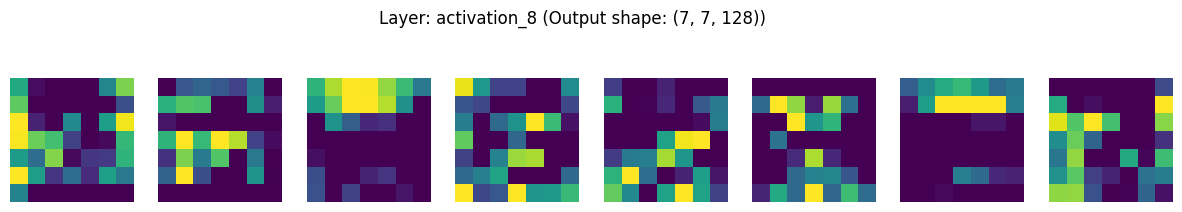

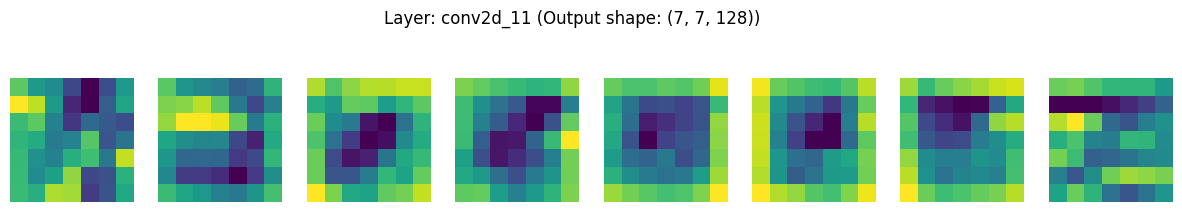

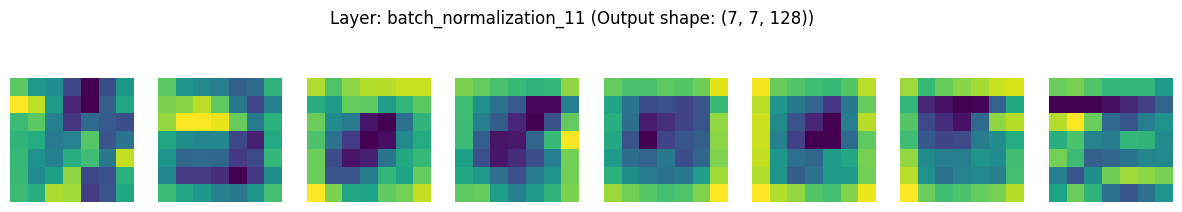

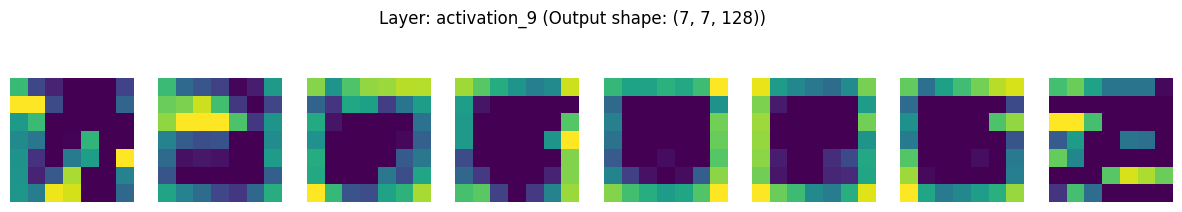

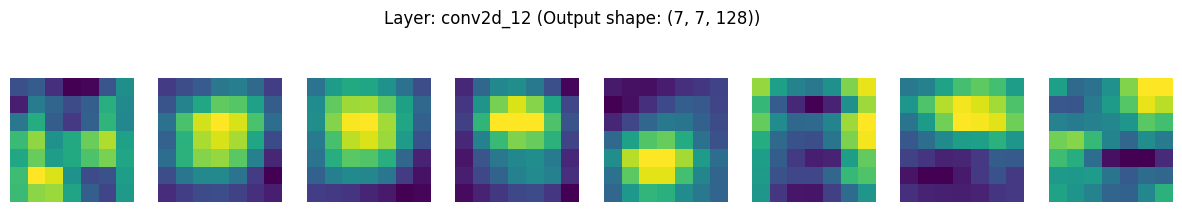

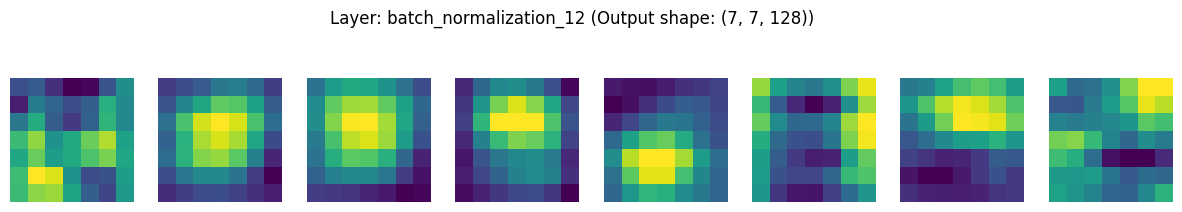

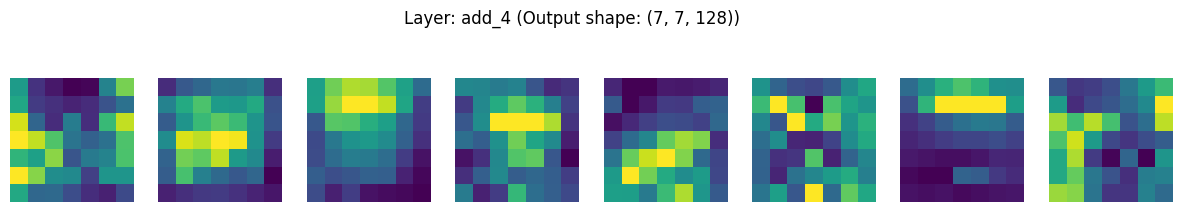

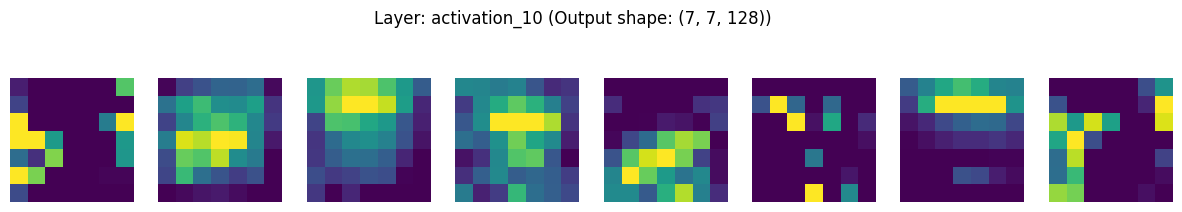

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import models

# Choose a sample image from the test set
sample_image = x_test[0:1]

# Identify and filter out Fully Connected (Dense) and global pooling layers
layer_outputs = []
layer_names = []

for layer in model_cnn.layers:
    # Skip Input, GlobalAveragePooling2D, and Dense layers
    if 'input' in layer.name or 'global_average_pooling' in layer.name or 'dense' in layer.name:
        continue
    layer_outputs.append(layer.output)
    layer_names.append(layer.name)

# Create an activation model to output all selected intermediate layers
visualization_model = models.Model(inputs=model_cnn.input, outputs=layer_outputs)
activations = visualization_model.predict(sample_image)

# Visualize a subset of channels (up to 8) for each layer
for layer_name, layer_activation in zip(layer_names, activations):
    # Layer activations shape: (1, height, width, channels)
    n_features = layer_activation.shape[-1]
    size_h = layer_activation.shape[1]
    size_w = layer_activation.shape[2]

    # Display up to 8 channels
    display_grid_cols = min(8, n_features)

    fig, axes = plt.subplots(1, display_grid_cols, figsize=(15, 2))
    fig.suptitle(f"Layer: {layer_name} (Output shape: {layer_activation.shape[1:]})", fontsize=12, y=1.15)

    # If there is only one column, wrap it in a list so we can iterate
    if display_grid_cols == 1:
        axes = [axes]

    for col in range(display_grid_cols):
        ax = axes[col]
        # Extract and normalize the channel for better rendering
        channel_image = layer_activation[0, :, :, col]
        channel_image -= channel_image.mean()
        channel_image /= (channel_image.std() + 1e-5)
        channel_image *= 64
        channel_image += 128
        channel_image = np.clip(channel_image, 0, 255).astype('uint8')

        ax.imshow(channel_image, cmap='viridis')
        ax.axis('off')

    plt.show()

## Visualize misclassified Test images

Identify where the model made errors on the Test set, and plot these misclassified images along with their true labels and predicted labels.

Total misclassified images: 49 out of 10000


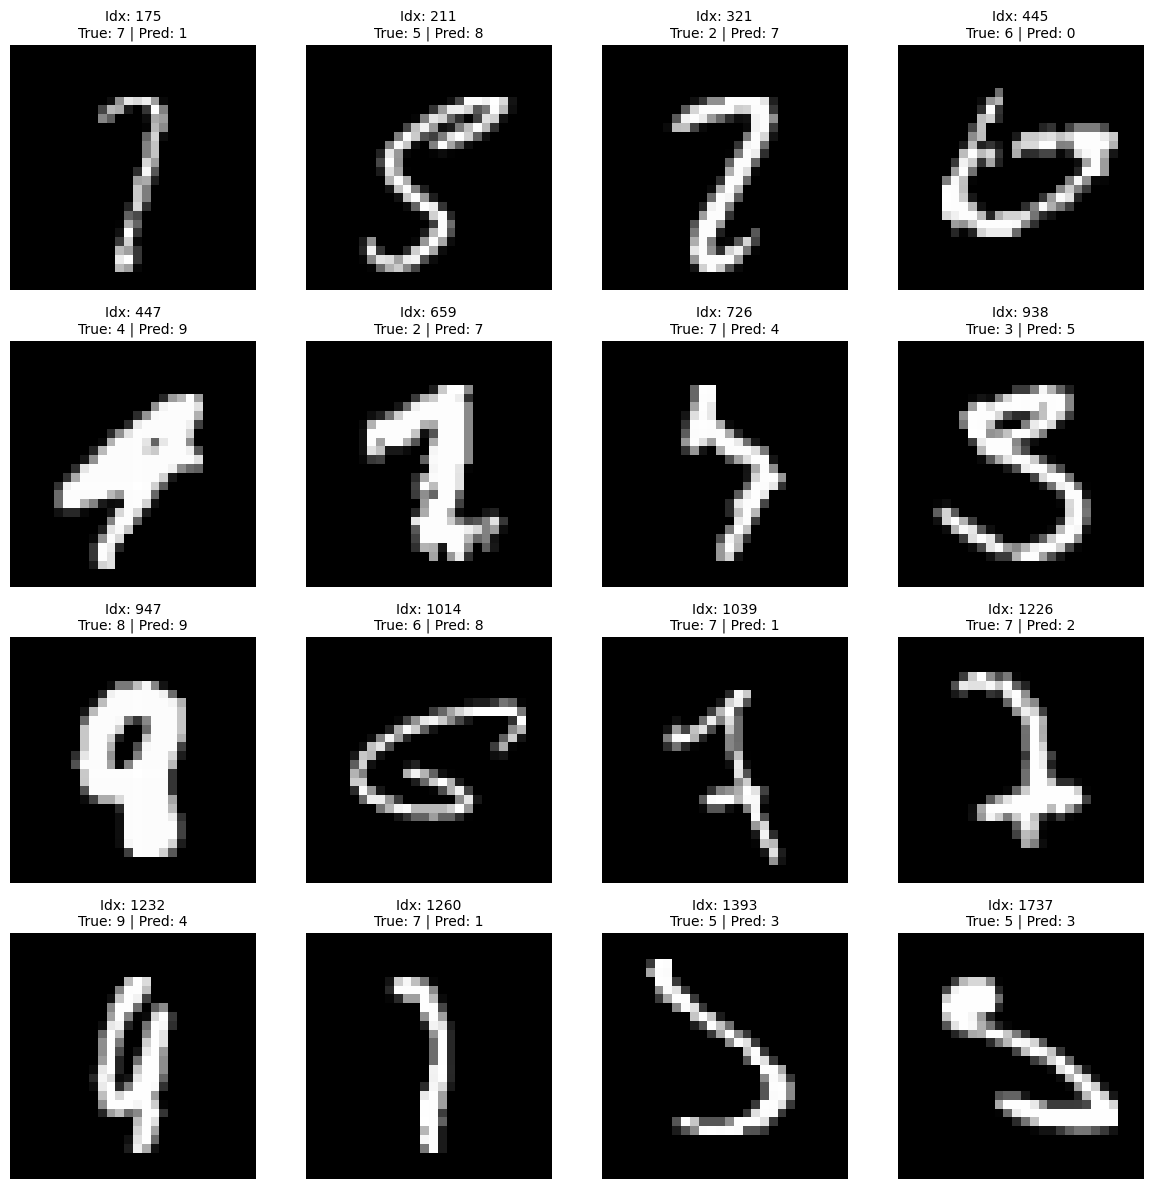

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Get predictions for the entire test set
y_pred_probs = model_cnn.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Identify indices where predictions do not match actual labels
misclassified_indices = np.where(y_pred != y_test)[0]
print(f"Total misclassified images: {len(misclassified_indices)} out of {len(x_test)}")

# Plot a grid of misclassified images
num_to_plot = min(16, len(misclassified_indices))
cols = 4
rows = (num_to_plot + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
axes = axes.flatten() if num_to_plot > 1 else [axes]

for i in range(num_to_plot):
    idx = misclassified_indices[i]
    img = x_test[idx].squeeze()
    true_label = y_test[idx]
    pred_label = y_pred[idx]

    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Idx: {idx}\nTrue: {true_label} | Pred: {pred_label}", fontsize=10)
    axes[i].axis('off')

# Turn off unused subplots
for j in range(num_to_plot, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()